In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../data/advertising_data.csv")

df.head()

,TV,Radio,Newspaper,Sales
0,118.616634,2.540030,64.561133,9.273464
1,285.707149,32.184110,9.329857,20.402740
2,222.278243,16.403443,17.001243,20.345036
3,183.610960,25.919964,89.956865,17.735666
4,55.245406,45.470757,61.036477,9.986713


In [4]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (100, 3)
y shape: (100,)


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(80, 3)
(20, 3)


In [6]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [7]:
y_pred = model.predict(X_test)

print(y_pred[:5])

[12.19088563 20.71737805 21.48362214 13.88791957  9.1599209 ]


In [8]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 2.1377670430188394
MSE: 8.406318244785139
RMSE: 2.89936514512835
R2 Score: 0.6984441202141196


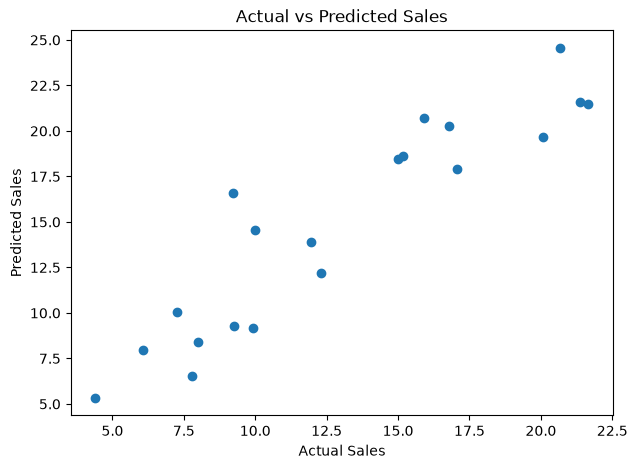

In [9]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.show()

In [10]:
import joblib

joblib.dump(model, "../models/linear_regression_model.pkl")

print("Model saved successfully!")

Model saved successfully!
